In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv("../data/KC1.csv")

In [4]:
df.head()

,LOC_BLANK,BRANCH_COUNT,LOC_CODE_AND_COMMENT,LOC_COMMENTS,CYCLOMATIC_COMPLEXITY,DESIGN_COMPLEXITY,ESSENTIAL_COMPLEXITY,LOC_EXECUTABLE,HALSTEAD_CONTENT,HALSTEAD_DIFFICULTY,...,HALSTEAD_LENGTH,HALSTEAD_LEVEL,HALSTEAD_PROG_TIME,HALSTEAD_VOLUME,NUM_OPERANDS,NUM_OPERATORS,NUM_UNIQUE_OPERANDS,NUM_UNIQUE_OPERATORS,LOC_TOTAL,Defective
0,9.0,11.0,0.0,0.0,6.0,5.0,5.0,29.0,26.93,18.90,...,95.0,0.05,534.42,508.97,36.0,59.0,20.0,21.0,41.0,b'Y'
1,0.0,1.0,0.0,0.0,1.0,1.0,1.0,3.0,16.73,3.00,...,14.0,0.33,8.36,50.19,6.0,8.0,6.0,6.0,7.0,b'N'
2,18.0,31.0,0.0,27.0,16.0,13.0,12.0,137.0,86.96,33.60,...,437.0,0.03,5454.40,2922.00,180.0,257.0,75.0,28.0,184.0,b'Y'
3,1.0,5.0,0.0,1.0,3.0,2.0,1.0,18.0,22.33,14.18,...,70.0,0.07,249.48,316.65,26.0,44.0,11.0,12.0,23.0,b'Y'
4,5.0,17.0,0.0,7.0,9.0,8.0,1.0,82.0,69.72,22.29,...,274.0,0.04,1924.82,1554.24,107.0,167.0,36.0,15.0,96.0,b'Y'


In [11]:
df.sum()

LOC_BLANK                                                           3483.0
BRANCH_COUNT                                                        8477.0
LOC_CODE_AND_COMMENT                                                 241.0
LOC_COMMENTS                                                        1921.0
CYCLOMATIC_COMPLEXITY                                               4840.0
DESIGN_COMPLEXITY                                                   4256.0
ESSENTIAL_COMPLEXITY                                                2549.0
LOC_EXECUTABLE                                                     28281.0
HALSTEAD_CONTENT                                                  36860.58
HALSTEAD_DIFFICULTY                                               12136.36
HALSTEAD_EFFORT                                                10782643.83
HALSTEAD_ERROR_EST                                                  170.65
HALSTEAD_LENGTH                                                    95914.0
HALSTEAD_LEVEL           

In [13]:
df.isnull().sum()

LOC_BLANK                0
BRANCH_COUNT             0
LOC_CODE_AND_COMMENT     0
LOC_COMMENTS             0
CYCLOMATIC_COMPLEXITY    0
DESIGN_COMPLEXITY        0
ESSENTIAL_COMPLEXITY     0
LOC_EXECUTABLE           0
HALSTEAD_CONTENT         0
HALSTEAD_DIFFICULTY      0
HALSTEAD_EFFORT          0
HALSTEAD_ERROR_EST       0
HALSTEAD_LENGTH          0
HALSTEAD_LEVEL           0
HALSTEAD_PROG_TIME       0
HALSTEAD_VOLUME          0
NUM_OPERANDS             0
NUM_OPERATORS            0
NUM_UNIQUE_OPERANDS      0
NUM_UNIQUE_OPERATORS     0
LOC_TOTAL                0
Defective                0
dtype: int64

In [14]:
df.shape

(1183, 22)

In [15]:
df['Defective']

0       b'Y'
1       b'N'
2       b'Y'
3       b'Y'
4       b'Y'
        ... 
1178    b'Y'
1179    b'Y'
1180    b'N'
1181    b'N'
1182    b'Y'
Name: Defective, Length: 1183, dtype: str

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1183 entries, 0 to 1182
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   LOC_BLANK              1183 non-null   float64
 1   BRANCH_COUNT           1183 non-null   float64
 2   LOC_CODE_AND_COMMENT   1183 non-null   float64
 3   LOC_COMMENTS           1183 non-null   float64
 4   CYCLOMATIC_COMPLEXITY  1183 non-null   float64
 5   DESIGN_COMPLEXITY      1183 non-null   float64
 6   ESSENTIAL_COMPLEXITY   1183 non-null   float64
 7   LOC_EXECUTABLE         1183 non-null   float64
 8   HALSTEAD_CONTENT       1183 non-null   float64
 9   HALSTEAD_DIFFICULTY    1183 non-null   float64
 10  HALSTEAD_EFFORT        1183 non-null   float64
 11  HALSTEAD_ERROR_EST     1183 non-null   float64
 12  HALSTEAD_LENGTH        1183 non-null   float64
 13  HALSTEAD_LEVEL         1183 non-null   float64
 14  HALSTEAD_PROG_TIME     1183 non-null   float64
 15  HALSTEAD_VOLUME

so all are float except for the target column 
it is in (Y/N) ------so obviously we are supposed to convert it into (1/0) binary form 
like y means the code/ software has bugs 
then n means the code is safe with no bugs



In [19]:
df["Defective"].value_counts()

Defective
b'N'    869
b'Y'    314
Name: count, dtype: int64

In [20]:
df.describe()

,LOC_BLANK,BRANCH_COUNT,LOC_CODE_AND_COMMENT,LOC_COMMENTS,CYCLOMATIC_COMPLEXITY,DESIGN_COMPLEXITY,ESSENTIAL_COMPLEXITY,LOC_EXECUTABLE,HALSTEAD_CONTENT,HALSTEAD_DIFFICULTY,...,HALSTEAD_ERROR_EST,HALSTEAD_LENGTH,HALSTEAD_LEVEL,HALSTEAD_PROG_TIME,HALSTEAD_VOLUME,NUM_OPERANDS,NUM_OPERATORS,NUM_UNIQUE_OPERANDS,NUM_UNIQUE_OPERATORS,LOC_TOTAL
count,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,...,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000
mean,2.944210,7.165680,0.203719,1.623838,4.091293,3.597633,2.154691,23.906171,31.158563,10.258969,...,0.144252,81.076923,0.199611,506.369941,432.761133,30.794590,50.282333,14.918850,10.501268,31.950972
std,4.721904,9.534669,0.903042,3.970237,4.771792,4.137288,2.802690,28.562998,23.314468,8.787196,...,0.210707,99.961431,0.261933,1249.566331,632.176312,38.358549,61.964496,13.720876,5.767180,34.974092
min,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,6.000000,14.720000,3.750000,...,0.020000,18.000000,0.070000,13.175000,62.910000,7.000000,11.000000,5.000000,6.000000,10.000000
50%,1.000000,3.000000,0.000000,0.000000,2.000000,2.000000,1.000000,14.000000,25.660000,7.710000,...,0.060000,43.000000,0.120000,86.440000,191.760000,17.000000,27.000000,11.000000,10.000000,20.000000
75%,3.000000,9.000000,0.000000,2.000000,5.000000,4.000000,1.000000,33.000000,42.580000,14.360000,...,0.180000,106.500000,0.230000,411.680000,544.510000,40.000000,66.000000,21.000000,14.000000,41.000000
max,58.000000,89.000000,12.000000,44.000000,45.000000,45.000000,26.000000,262.000000,193.060000,53.750000,...,2.640000,1106.000000,2.000000,18044.640000,7918.820000,428.000000,678.000000,120.000000,37.000000,288.000000


there exists class imbalance

In [21]:
import matplotlib.pyplot as plt

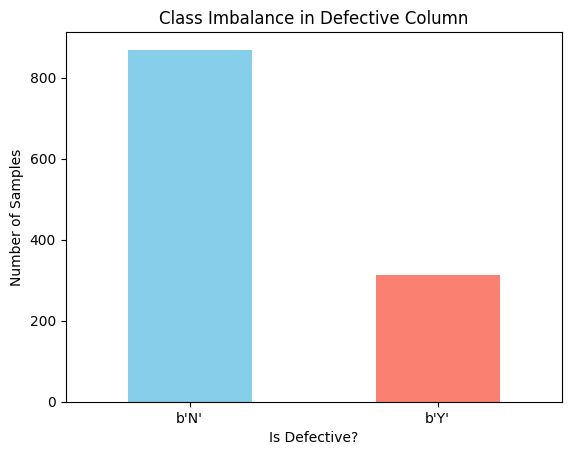

In [23]:
import matplotlib.pyplot as plt

# 1. Count the values and make a bar chart
df["Defective"].value_counts().plot(kind="bar", color=["skyblue", "salmon"])

# 2. Add labels so it's easy to read
plt.title("Class Imbalance in Defective Column")
plt.xlabel("Is Defective?")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)  # Keeps 'b'N'' and 'b'Y'' upright

# 3. Show the plot
plt.show()

#df['Defective'].value_counts(): Automatically groups your 869 b'N' and 314 b'Y' rows.

In [24]:
df["Defective"].value_counts(normalize=True) * 100

Defective
b'N'    73.457312
b'Y'    26.542688
Name: proportion, dtype: float64